# EDA básico e inspección de calidad ECYL

Lo primero es importar las librerías que vamos a usar.

In [1]:
import requests
import os
import pandas as pd
import json
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
api_key = os.environ.get("API_KEY")
headers = {
    "Authorization": f"Apikey {api_key}",
    "Content-Type": "application/json"
}

Prueba de que se ha podido acceder a la API

In [3]:
url = "https://analisis.datosabiertos.jcyl.es/api/explore/v2.1/catalog/datasets/ofertas-de-empleo/records/"

limite = 100
offset = 0
todos_los_registros = []
total = None

while total is None or offset < total:
    respuesta = requests.get(
        url,
        params={"lang": "es", "limit": limite, "offset": offset},
        timeout=30
    )
    respuesta.raise_for_status()

    pagina = respuesta.json()
    total = pagina["total_count"]
    registros = pagina["results"]

    if not registros:
        break

    todos_los_registros.extend(registros)
    offset += len(registros)

print(f"Descargados {len(todos_los_registros)} de {total} registros")

with open("respuestas.json", "w", encoding="utf-8") as archivo:
    json.dump(
        {"total_count": total, "results": todos_los_registros},
        archivo,
        ensure_ascii=False,
        indent=2
    )

Descargados 1027 de 1027 registros


# Carga de datos

Mostramos que se han obtenido correctamente

In [4]:
with open("respuestas.json", "r", encoding="utf-8") as archivo:
    datos = json.load(archivo)

df = pd.json_normalize(datos["results"])

print(df.shape)  # filas y columnas
df.head()

(1027, 16)


,titulo,provincia,fecha_publicacion,descripcion,provincia_alternativa,fuente_contenido,localidad_asset,localidad_asset0,localidad_asset2,documentos_asociados,identificador,actualizacionmetadatos,enlace_al_contenido,geografico.lon,geografico.lat,geografico
0,"COCINEROS, EN GENERAL",Palencia,2026-10-12,"<p>COCINEROS, PARA DUEÑAS. LABORAL INDEFINIDO ...",NaN,ECYL,1179298081851,Dueñas,34.0,None,1285689059800,2026-10-12,https://datosabiertos.jcyl.es/web/jcyl/Empleo/...,-4.546755,41.877316,NaN
1,"COCINEROS, EN GENERAL",Soria,2026-10-11,<p>OFERTA 21165. HOTEL EN EL BURGO DE OSMA (SO...,NaN,ECYL,1179469126353,Burgo de Osma-Ciudad de Osma,42.0,None,1285689059772,2026-10-12,https://datosabiertos.jcyl.es/web/jcyl/Empleo/...,-3.075403,41.588287,NaN
2,TERAPEUTAS OCUPACIONALES,León,2026-10-11,"<p>Para más información acuda a <a href=""http:...",NaN,ECYL,1179297955047,Soto de la Vega,24.0,None,1285689059856,2026-10-12,https://datosabiertos.jcyl.es/web/jcyl/Empleo/...,-5.882215,42.332270,NaN
3,"PEONES DE LA INDUSTRIA DE LA ALIMENTACIÓN, BEB...",Salamanca,2026-10-10,"<p>Para más información acuda a <a href=""http:...",NaN,ECYL,1179298266466,Ledrada,37.0,None,1285689059884,2026-10-12,https://datosabiertos.jcyl.es/web/jcyl/Empleo/...,-5.720769,40.469257,NaN
4,Técnico/a Medio de Contabilidad para Diputació...,Palencia,2026-10-09,<p><strong>Convoca: </strong> Diputación de Pa...,NaN,Organismo oficial,NaN,NaN,NaN,None,1285688752400,2026-10-09,https://datosabiertos.jcyl.es/web/jcyl/Empleo/...,NaN,NaN,NaN


# Estudio de la muestra

Mostramos la dimensión del dataset

In [5]:
registros = df.shape[0]
columnas = df.shape[1]
print(f"El DataFrame tiene {registros} registros y {columnas} columnas.")

El DataFrame tiene 1027 registros y 16 columnas.


Comprobamos de que tipo son las columnas del dataset

In [6]:
for columna in df.columns:
    print(f"{columna}: {df[columna].dtype}")

titulo: str
provincia: str
fecha_publicacion: str
descripcion: str
provincia_alternativa: str
fuente_contenido: str
localidad_asset: str
localidad_asset0: str
localidad_asset2: float64
documentos_asociados: object
identificador: str
actualizacionmetadatos: str
enlace_al_contenido: str
geografico.lon: float64
geografico.lat: float64
geografico: float64


Podemos ver que la mayoría de columnas son cadenas de texto salvo localidad_asset2, geografico.lon, geografico.lat y geografico que son númericas. Documentos asociados es un object que también funciona como una cadena de texto.

# Estudio de Variables

### Estudio del título

La primera columna es el título

In [7]:
print("Número de valores únicos en la columna título:", df["titulo"].nunique())
print(df["titulo"].unique())

Número de valores únicos en la columna título: 441
<StringArray>
[                                                 'COCINEROS, EN GENERAL',
                                               'TERAPEUTAS OCUPACIONALES',
            'PEONES DE LA INDUSTRIA DE LA ALIMENTACIÓN, BEBIDAS Y TABACO',
            'Técnico/a Medio de Contabilidad para Diputación de Palencia',
             'Alguacil/a para Ayto. de Villamoratiel de las Matas (León)',
                                                      'PINCHES DE COCINA',
                                                  'CAMAREROS, EN GENERAL',
                                 'PODADORES Y/O MOTOSERRISTAS FORESTALES',
                                            'FISIOTERAPEUTAS, EN GENERAL',
              'MOZOS DE CARGA Y DESCARGA, ALMACÉN Y/O MERCADO DE ABASTOS',
 ...
                               'Técnico/a de Mantenimiento para Palencia',
          'Condutor/a repartidor/a para Villares de la Reina (Salamanca)',
                          'Téc

Como podemos observar, de los 1027 registros solo existen 441 valores únicos en la columna de títulos. En este dataset es la columna que le da nombre a la oferta de empleo. 

### Estudio de provincias

(np.float64(-1.099999267254143),
 np.float64(1.0999999642751983),
 np.float64(-1.0999967104876318),
 np.float64(1.0999998433565539))

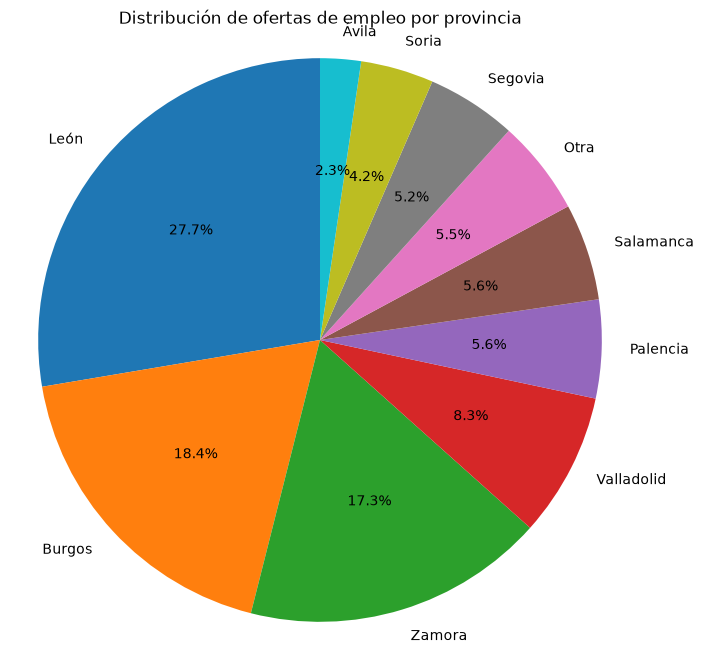

In [18]:
# Contar ofertas por provincia
ofertas_provincia = df["provincia"].value_counts()

# Crear gráfica circular
plt.figure(figsize=(8, 8))

plt.pie(
    ofertas_provincia,
    labels=ofertas_provincia.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribución de ofertas de empleo por provincia")
plt.axis("equal")

En este gráfico vemos que la mayoría de ofertas son de León, Burgos y Zamora, que ocupan casi dos tercios del dataset. El resto de ofertas se reparten entre las otras provincias. Siendo la que menos tiene Ávila y la que más León.

(np.float64(-1.0999962084067674),
 np.float64(1.0999998194479412),
 np.float64(-1.0999962084067674),
 np.float64(1.0999998194479412))

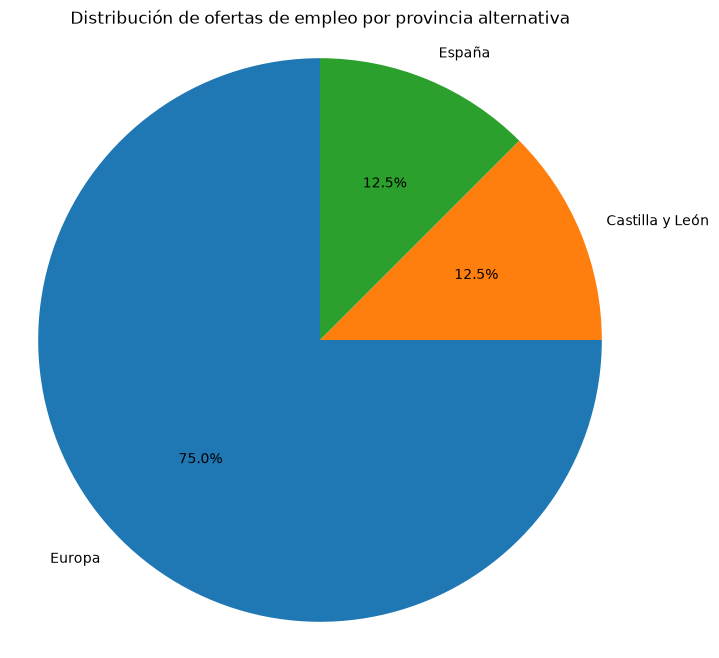

In [19]:
# Contar ofertas por provincia
ofertas_provincia = df["provincia_alternativa"].value_counts()

# Crear gráfica circular
plt.figure(figsize=(8, 8))

plt.pie(
    ofertas_provincia,
    labels=ofertas_provincia.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribución de ofertas de empleo por provincia alternativa")
plt.axis("equal")

Las columnas de provincia y provincia alternativa contienen los lugares donde se van a llevar a cabo los trabajos de las ofertas. En estas gráficas podemos ver la distribución de las provincias. La columna provincia es una que está dedicada a provincias que se encuentran en Castilla y León. Mientras que la de provincia alternativa son para ofertas que se encuentran fuera de la comunidad autónoma o que abarcan a toda la comunidad.

Las columnas de localidad_asset son columnas que continen el municipio en el que se va a realizar el trabajo. La primera es un identificador, la segunda es el nombre del municipio y la tercera contiene otro número asociado con la localidad.

### Estudio de las descripciones

In [20]:
print("Numero de valores únicos en la columna descripcion:", df["descripcion"].nunique())
print(df["descripcion"].unique())

Numero de valores únicos en la columna descripcion: 1024
<StringArray>
[                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

Como podemos ver la columna de descripciones no tiene casi valores repetidos. Esta columna tiene la función de dar detalles sobre el empleo de la oferta. Columna muy importante para poder ver la compatibilidad del usuario con la oferta del empleo.

### Estudio de fechas

In [21]:
print("Numero de valores únicos en la columna fecha_publicacion:", df["fecha_publicacion"].nunique())
print(df["fecha_publicacion"].unique())

Numero de valores únicos en la columna fecha_publicacion: 127
<StringArray>
['2026-10-12', '2026-10-11', '2026-10-10', '2026-10-09', '2026-10-08',
 '2026-10-07', '2026-10-06', '2026-10-05', '2026-10-04', '2026-10-03',
 ...
 '2026-08-12', '2026-07-12', '2026-06-15', '2026-06-09', '2026-06-07',
 '2026-05-22', '2026-05-19', '2026-05-11', '2026-11-18', '2026-11-20']
Length: 127, dtype: str


In [22]:
print("Número de valores únicos en la columna actualizacionmetadatos:", df["actualizacionmetadatos"].nunique())
print(df["actualizacionmetadatos"].unique())

Número de valores únicos en la columna actualizacionmetadatos: 91
<StringArray>
['2026-10-12', '2026-10-09', '2026-10-08', '2026-10-07', '2026-10-06',
 '2026-10-05', '2026-10-02', '2026-10-01', '2026-09-30', '2026-09-29',
 '2026-09-28', '2026-09-25', '2026-09-24', '2026-09-23', '2026-09-21',
 '2026-09-18', '2026-09-16', '2026-09-15', '2026-09-11', '2026-09-10',
 '2026-09-09', '2026-09-08', '2026-09-07', '2026-09-02', '2026-09-01',
 '2026-08-27', '2026-08-25', '2026-08-24', '2026-08-21', '2026-08-19',
 '2026-08-18', '2026-08-17', '2026-08-14', '2026-08-28', '2026-08-10',
 '2026-08-06', '2026-08-04', '2026-08-03', '2026-08-13', '2026-07-29',
 '2026-07-27', '2026-08-31', '2026-07-20', '2026-07-13', '2026-08-11',
 '2026-07-01', '2026-07-30', '2026-06-18', '2026-07-10', '2026-08-20',
 '2026-07-23', '2026-05-20', '2026-05-18', '2026-09-22', '2026-04-29',
 '2026-04-01', '2026-10-13', '2026-10-14', '2026-10-15', '2026-10-16',
 '2026-10-19', '2026-10-20', '2026-10-21', '2026-10-22', '2026-10-23

La columna de fecha_publicacion es el lugar donde se data la fecha en la que se realizó la publicación de la oferta de empleo. Las fechas coinciden en muchas ofertas de empleo. La columna de actualizacionmetadatos contiene la fecha en la que los datos de la oferta han sido actualizados por útlima vez.

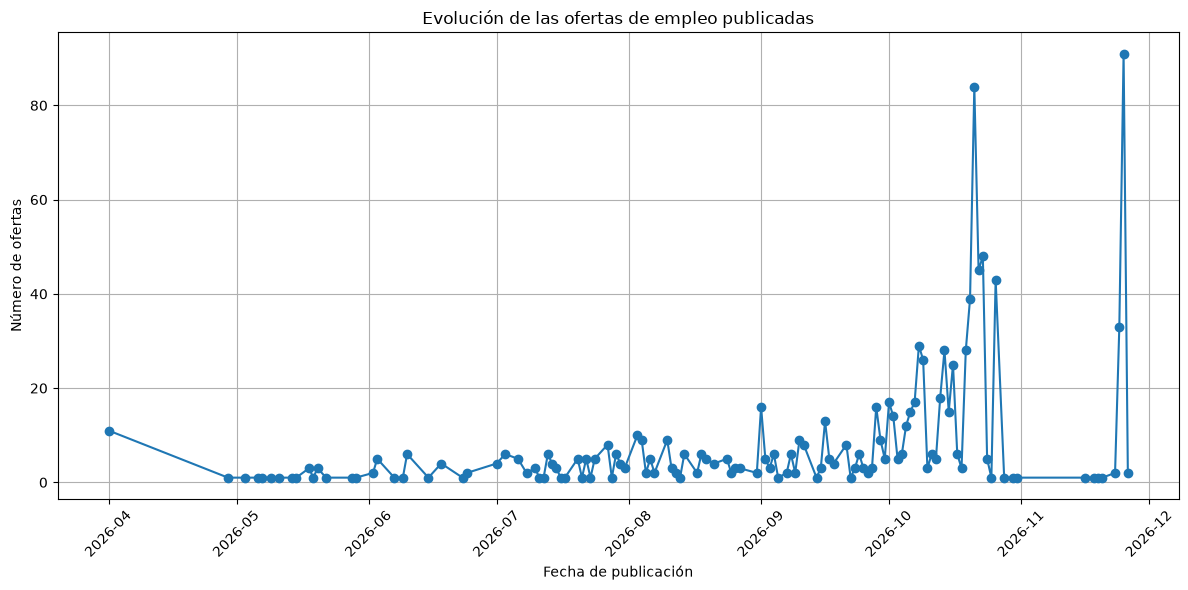

In [23]:
# Convertir fechas a formato datetime
df["fecha_publicacion"] = pd.to_datetime(
    df["fecha_publicacion"],
    errors="coerce"
)

# Contar ofertas por fecha
ofertas_fecha = (
    df.groupby("fecha_publicacion")
    .size()
    .sort_index()
)

# Crear gráfica
plt.figure(figsize=(12, 6))

plt.plot(
    ofertas_fecha.index,
    ofertas_fecha.values,
    marker="o",
    linestyle="-"
)

plt.title("Evolución de las ofertas de empleo publicadas")
plt.xlabel("Fecha de publicación")
plt.ylabel("Número de ofertas")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

Podemos ver que las ofertas publicadas en su mayoría son bastante recientes, siendo que están publicadas en octubre y noviembre principalmente. Aunque hay ofertas que se remontan a Abril.

### Estudio de columnas con valores únicos

Las columnas geográficas contienen los puntos geográficos de los lugares donde se realizaran los trabajos. Están divididas en la columnade latitud, de longitud y el punto completo.

In [12]:
print("Número de valores únicos en la columna identificador:", df["identificador"].nunique())
print(df["identificador"].unique())

Número de valores únicos en la columna identificador: 1027
<StringArray>
['1285689059800', '1285689059772', '1285689059856', '1285689059884',
 '1285688752400', '1285688741007', '1285688777604', '1285688636501',
 '1285688636081', '1285688593879',
 ...
 '1285701423011', '1285701423095', '1285701411818', '1285701271826',
 '1285701412123', '1285701232857', '1285701412253', '1285701271891',
 '1285701333113', '1285701333503']
Length: 1027, dtype: str


La columna de identificador contiene un número que identifica cada oferta de empleo. Es la columna que no tiene ningú valor repetido. La columna clave para diferenciar los registros. Está en formato de cadena de texto.

In [16]:
print("Número de valores únicos en la columna enlace_al_contenido:", df["enlace_al_contenido"].nunique())
print(df["enlace_al_contenido"].unique())

Número de valores únicos en la columna enlace_al_contenido: 1027
<StringArray>
['https://datosabiertos.jcyl.es/web/jcyl/Empleo/es/Plantilla100Detalle/1284216458054/OfertasEmpleo/1285689059800/Empleo',
 'https://datosabiertos.jcyl.es/web/jcyl/Empleo/es/Plantilla100Detalle/1284216458054/OfertasEmpleo/1285689059772/Empleo',
 'https://datosabiertos.jcyl.es/web/jcyl/Empleo/es/Plantilla100Detalle/1284216458054/OfertasEmpleo/1285689059856/Empleo',
 'https://datosabiertos.jcyl.es/web/jcyl/Empleo/es/Plantilla100Detalle/1284216458054/OfertasEmpleo/1285689059884/Empleo',
 'https://datosabiertos.jcyl.es/web/jcyl/Empleo/es/Plantilla100Detalle/1284216458054/OfertasEmpleo/1285688752400/Empleo',
 'https://datosabiertos.jcyl.es/web/jcyl/Empleo/es/Plantilla100Detalle/1284216458054/OfertasEmpleo/1285688741007/Empleo',
 'https://datosabiertos.jcyl.es/web/jcyl/Empleo/es/Plantilla100Detalle/1284216458054/OfertasEmpleo/1285688777604/Empleo',
 'https://datosabiertos.jcyl.es/web/jcyl/Empleo/es/Plantilla100Deta

La columna de enlace_al_contenido también es única porque contiene el enlace a la oferta de empleo original.

### Estudio de fuentes

In [13]:
print("Número de valores únicos en la columna fuente_contenido:", df["fuente_contenido"].nunique())
print(df["fuente_contenido"].unique())

Número de valores únicos en la columna fuente_contenido: 4
<StringArray>
['ECYL', 'Organismo oficial', 'Red EURES', 'Internet / Prensa']
Length: 4, dtype: str


La columna de fuente de contenido nos indica la procedencia de la oferta de empleo. Solo tiene cuatro valores únicos.

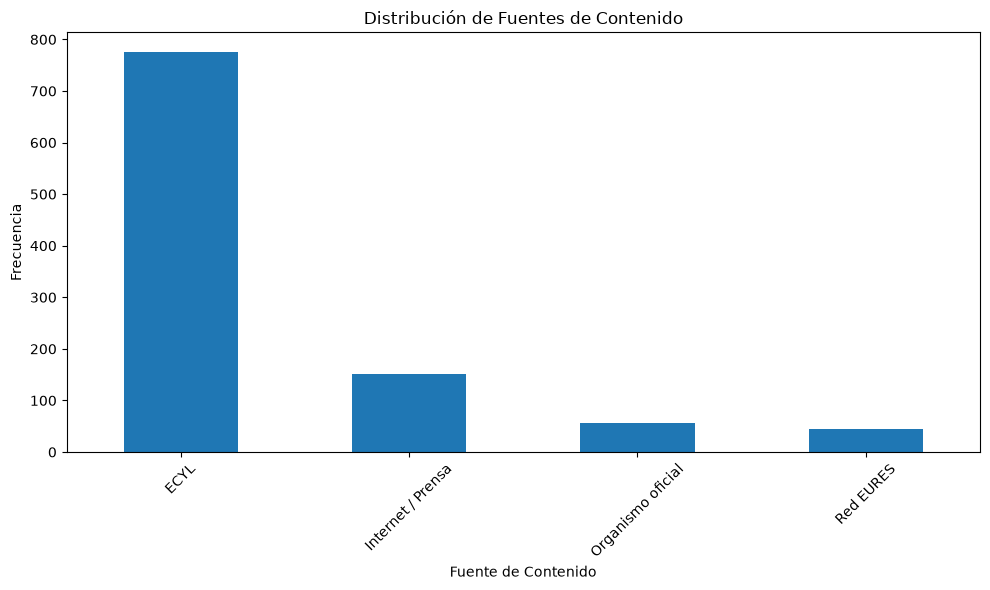

In [14]:
# Calcular la frecuencia de cada fuente de contenido
frecuencias_fuente = df["fuente_contenido"].value_counts().sort_index()

# Crear un gráfico de barras para visualizar la distribución de fuentes de contenido
plt.figure(figsize=(10, 6))
frecuencias_fuente.plot(kind="bar")

# Agregar etiquetas y título al gráfico
plt.xlabel("Fuente de Contenido")
plt.ylabel("Frecuencia")
plt.title("Distribución de Fuentes de Contenido")
plt.xticks(rotation=45)
plt.tight_layout()

# Mostrar el gráfico
plt.show()


Como podemos comprobar en el gráfico la mayoría de ofertas provienen del propio portal de empleo, llegando a casi las 800, seguida de internet y la prensa que pasan de las 100 y luego quedan los organismos oficiales y la red EULERS que no pasan de las 100.

### Columnas vacías

Las columnas de documentos asociados y geográfico están vacías.

In [15]:
columnas_nulas = df.columns[df.isna().all(axis=0)]
print(columnas_nulas)   

Index(['documentos_asociados', 'geografico'], dtype='str')


# Conclusión

Las columnas con los valores más importantes son: título, provincia, fecha_publicación y descripción. De estos datos podemos sacar valores de compatibilidad con los perfiles de los candidatos a las ofertas. Otras columnas que son de mucha utilidad son la de identificador y la de url, para diferenciar las ofertas. La columna de localidad y la de puntos geográficos puede servir para ser más precisos a la hora de seleccionar ofertas más cercanas al candidato. Por último la columna de actualización de metadatos para saber cuando se actualizó el registro y tener la base actualizada.

Esta base de datos tiene variables que son potencialmente interesantes para el proyecto pero le faltan otras variables que son necesarias como la experiencia requerida, titulación necesaria, salario y otros valores. Además de que tiene pocos registros en comparación. Puede ser una base de datos de apoyo. 